In [1]:
import re
import pandas as pd
import numpy as np
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
import transformers
from transformers import pipeline

The cache for model files in Transformers v4.22.0 has been updated. Migrating your old cache. This is a one-time only operation. You can interrupt this and resume the migration later on by calling `transformers.utils.move_cache()`.


0it [00:00, ?it/s]

In [2]:
data = pd.read_csv('book_reviews_sample.csv')
data.head()

,index,reviewText,rating
0,11494,Clean and funny. A bit busy with all the diffe...,3
1,984,Alex a sexy hot cop and the PhD candidate. Wha...,4
2,1463,Good thing that this is a free story. I read i...,1
3,10342,"Action, action, action! Equipment keeps gettin...",4
4,5256,this was hands down the worse book i have ever...,1


In [3]:
data['reviewText_lowercase'] = data['reviewText'].str.lower()
data.head()

,index,reviewText,rating,reviewText_lowercase
0,11494,Clean and funny. A bit busy with all the diffe...,3,clean and funny. a bit busy with all the diffe...
1,984,Alex a sexy hot cop and the PhD candidate. Wha...,4,alex a sexy hot cop and the phd candidate. wha...
2,1463,Good thing that this is a free story. I read i...,1,good thing that this is a free story. i read i...
3,10342,"Action, action, action! Equipment keeps gettin...",4,"action, action, action! equipment keeps gettin..."
4,5256,this was hands down the worse book i have ever...,1,this was hands down the worse book i have ever...


In [4]:
data['reviewText_clean'] = data.apply(lambda x: re.sub(r'[^\w\s]', '', x['reviewText_lowercase']), axis = 1)
data.head()

,index,reviewText,rating,reviewText_lowercase,reviewText_clean
0,11494,Clean and funny. A bit busy with all the diffe...,3,clean and funny. a bit busy with all the diffe...,clean and funny a bit busy with all the differ...
1,984,Alex a sexy hot cop and the PhD candidate. Wha...,4,alex a sexy hot cop and the phd candidate. wha...,alex a sexy hot cop and the phd candidate what...
2,1463,Good thing that this is a free story. I read i...,1,good thing that this is a free story. i read i...,good thing that this is a free story i read it...
3,10342,"Action, action, action! Equipment keeps gettin...",4,"action, action, action! equipment keeps gettin...",action action action equipment keeps getting b...
4,5256,this was hands down the worse book i have ever...,1,this was hands down the worse book i have ever...,this was hands down the worse book i have ever...


In [5]:
sentiment_analysis = SentimentIntensityAnalyzer()

In [6]:
data['sent_analysis'] = data['reviewText_clean'].apply(lambda x: sentiment_analysis.polarity_scores(x)['compound'])
data.head(10)

,index,reviewText,rating,reviewText_lowercase,reviewText_clean,sent_analysis
0,11494,Clean and funny. A bit busy with all the diffe...,3,clean and funny. a bit busy with all the diffe...,clean and funny a bit busy with all the differ...,0.7684
1,984,Alex a sexy hot cop and the PhD candidate. Wha...,4,alex a sexy hot cop and the phd candidate. wha...,alex a sexy hot cop and the phd candidate what...,0.9325
2,1463,Good thing that this is a free story. I read i...,1,good thing that this is a free story. i read i...,good thing that this is a free story i read it...,0.6740
3,10342,"Action, action, action! Equipment keeps gettin...",4,"action, action, action! equipment keeps gettin...",action action action equipment keeps getting b...,0.6652
4,5256,this was hands down the worse book i have ever...,1,this was hands down the worse book i have ever...,this was hands down the worse book i have ever...,-0.4767
5,7277,"Great book packed full with fast cars , crazy ...",4,"great book packed full with fast cars , crazy ...",great book packed full with fast cars crazy h...,0.7269
6,9781,I enjoyed the reader's digest very much. If I ...,4,i enjoyed the reader's digest very much. if i ...,i enjoyed the readers digest very much if i co...,0.5106
7,4583,This series has been good and I look forward t...,5,this series has been good and i look forward t...,this series has been good and i look forward t...,0.7906
8,9797,I just could not get into this book.I all ways...,1,i just could not get into this book.i all ways...,i just could not get into this booki all ways ...,0.0000
9,895,it was good to see where Dan and Elle was. And...,4,it was good to see where dan and elle was. and...,it was good to see where dan and elle was and ...,0.8107


In [7]:
bins = [-1, -0.1, 0.1, 1]
names = ['Negative', 'Neutral', 'Positive']


In [8]:
data['sent_analysis_label'] = pd.cut(data['sent_analysis'], bins, labels=names)
data.head(10)

,index,reviewText,rating,reviewText_lowercase,reviewText_clean,sent_analysis,sent_analysis_label
0,11494,Clean and funny. A bit busy with all the diffe...,3,clean and funny. a bit busy with all the diffe...,clean and funny a bit busy with all the differ...,0.7684,Positive
1,984,Alex a sexy hot cop and the PhD candidate. Wha...,4,alex a sexy hot cop and the phd candidate. wha...,alex a sexy hot cop and the phd candidate what...,0.9325,Positive
2,1463,Good thing that this is a free story. I read i...,1,good thing that this is a free story. i read i...,good thing that this is a free story i read it...,0.6740,Positive
3,10342,"Action, action, action! Equipment keeps gettin...",4,"action, action, action! equipment keeps gettin...",action action action equipment keeps getting b...,0.6652,Positive
4,5256,this was hands down the worse book i have ever...,1,this was hands down the worse book i have ever...,this was hands down the worse book i have ever...,-0.4767,Negative
5,7277,"Great book packed full with fast cars , crazy ...",4,"great book packed full with fast cars , crazy ...",great book packed full with fast cars crazy h...,0.7269,Positive
6,9781,I enjoyed the reader's digest very much. If I ...,4,i enjoyed the reader's digest very much. if i ...,i enjoyed the readers digest very much if i co...,0.5106,Positive
7,4583,This series has been good and I look forward t...,5,this series has been good and i look forward t...,this series has been good and i look forward t...,0.7906,Positive
8,9797,I just could not get into this book.I all ways...,1,i just could not get into this book.i all ways...,i just could not get into this booki all ways ...,0.0000,Neutral
9,895,it was good to see where Dan and Elle was. And...,4,it was good to see where dan and elle was. and...,it was good to see where dan and elle was and ...,0.8107,Positive


In [9]:
data['reviewText_clean'][8]

'i just could not get into this booki all ways read a book when i start it this one i could not'

<Axes: xlabel='sent_analysis_label'>

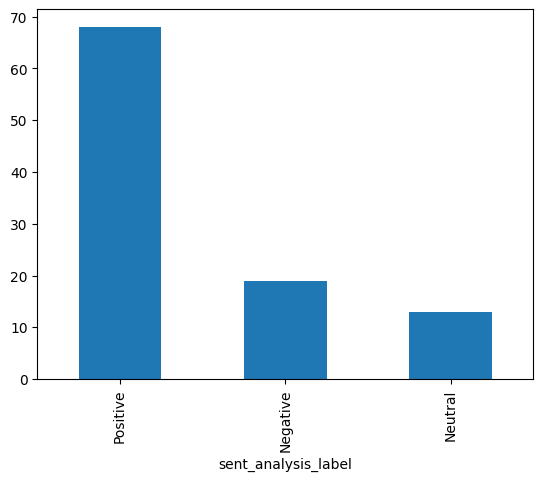

In [11]:
data['sent_analysis_label'].value_counts().plot.bar()

In [12]:
trans_pipeline = pipeline('sentiment-analysis')

No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f (https://huggingface.co/distilbert/distilbert-base-uncased-finetuned-sst-2-english).
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

Device set to use cpu


In [13]:
trans_labels = []
for review in data['reviewText_clean']:
    sent_list = trans_pipeline(review)
    sent_labels = [sent['label'] for sent in sent_list]
    trans_labels.append(sent_labels)
data['transformers_analysis'] = trans_labels
data.head(5)

,index,reviewText,rating,reviewText_lowercase,reviewText_clean,sent_analysis,sent_analysis_label,transformers_analysis
0,11494,Clean and funny. A bit busy with all the diffe...,3,clean and funny. a bit busy with all the diffe...,clean and funny a bit busy with all the differ...,0.7684,Positive,[POSITIVE]
1,984,Alex a sexy hot cop and the PhD candidate. Wha...,4,alex a sexy hot cop and the phd candidate. wha...,alex a sexy hot cop and the phd candidate what...,0.9325,Positive,[POSITIVE]
2,1463,Good thing that this is a free story. I read i...,1,good thing that this is a free story. i read i...,good thing that this is a free story i read it...,0.6740,Positive,[NEGATIVE]
3,10342,"Action, action, action! Equipment keeps gettin...",4,"action, action, action! equipment keeps gettin...",action action action equipment keeps getting b...,0.6652,Positive,[NEGATIVE]
4,5256,this was hands down the worse book i have ever...,1,this was hands down the worse book i have ever...,this was hands down the worse book i have ever...,-0.4767,Negative,[NEGATIVE]
